# Activity 4 - Graph Mining

ACH transaction volume from January to December 2023.

In [17]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# We load the CSV file
df = pd.read_csv("../jopacc_system_month_november_2022_to_june_2026.csv")

# We make sure the report month is an actual date
df["report_month"] = pd.to_datetime(df["report_month"])

# For this activity we only want the ACH payment system, and only the twelve months of 2023.
df = df[
    (df["system"] == "ACH") &
    (df["report_month"].dt.year == 2023)
].copy()

# We take the month number out of the date. We use it later to put the months back in order.
df["month"] = df["report_month"].dt.month

# Then we add up the total transactions for each month, which gives us the twelve values that
# the whole graph is built from.
monthly = df.groupby("month")["transactions_total"].sum().reset_index()

In [18]:
# We sort the twelve months from the lowest total to the highest one. 
monthly = monthly.sort_values("transactions_total").reset_index(drop=True)

# This is the column that holds the activity level of each month.
monthly["activity"] = ""

# We split the ranked months into four equal groups of three, so the three quietest months become Low and the three busiest months become Very High.
monthly.loc[0:2, "activity"] = "Low"
monthly.loc[3:5, "activity"] = "Medium"
monthly.loc[6:8, "activity"] = "High"
monthly.loc[9:11, "activity"] = "Very High"

# Now we put the months back into calendar order, because the graph has to follow what
# actually came after what.
monthly = monthly.sort_values("month").reset_index(drop=True)

# This is only here so the table shows the month names instead of their numbers.
month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

monthly["month_name"] = monthly["month"].map(month_names)
monthly[["month_name", "transactions_total", "activity"]]

,month_name,transactions_total,activity
0,January,875000,Medium
1,February,819000,Low
2,March,920000,High
3,April,893000,Medium
4,May,931000,Very High
5,June,890000,Medium
6,July,867000,Low
7,August,926000,Very High
8,September,742000,Low
9,October,1040000,Very High


In [19]:
# This is the activity level of every month read from January to December.
# The whole graph comes out of this one sequence.
sequence = monthly["activity"].tolist()
print(sequence)

# The four activity levels are the four nodes of the graph.
nodes = ["Low", "Medium", "High", "Very High"]

# The edges are the moves from one month to the month after it.
edges = [
    ("Medium", "Low"),
    ("Low", "High"),
    ("High", "Medium"),
    ("Medium", "Very High"),
    ("Very High", "Medium"),
    ("Low", "Very High"),
    ("Very High", "Low"),
    ("Very High", "High"),
    ("High", "High")
]

['Medium', 'Low', 'High', 'Medium', 'Very High', 'Medium', 'Low', 'Very High', 'Low', 'Very High', 'High', 'High']


## Directed Unweighted Graph

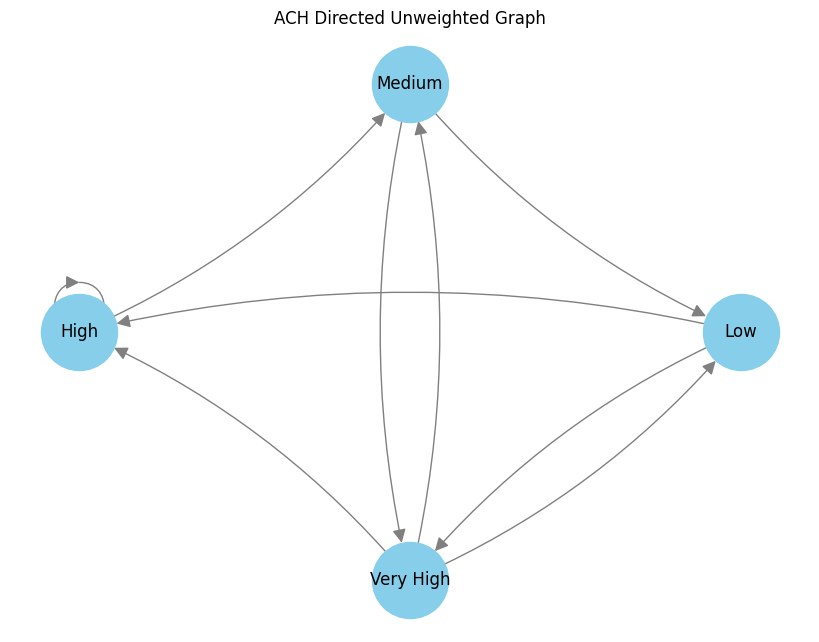

In [20]:
# We build the directed graph. It is directed because going from Low to High is not the samething as going from High to Low.
G = nx.DiGraph()
G.add_nodes_from(nodes)
G.add_edges_from(edges)

# Then we draw it. 
plt.figure(figsize=(8, 6))
pos = nx.circular_layout(G)

nx.draw(
    G,
    pos,
    with_labels=True,
    arrows=True,
    arrowsize=20,
    node_size=3000,
    node_color="skyblue",
    edge_color="gray",
    connectionstyle="arc3,rad=0.12"
)

plt.title("ACH Directed Unweighted Graph")
plt.show()

## Directed Graph Measures

In [21]:
# In-degree and out-degree 
print("In-Degree")
for node, value in G.in_degree():
    print(node, value)

print("\nOut-Degree")
for node, value in G.out_degree():
    print(node, value)

In-Degree
Low 2
Medium 2
High 3
Very High 2

Out-Degree
Low 2
Medium 2
High 2
Very High 3


In [22]:
# PageRank tells us which state is the most important one in the structure. A state scores highly when the states pointing at it also score highly. 
pagerank = nx.pagerank(G, alpha=1.0)

for node, value in pagerank.items():
    print(node, round(value, 3))

Low 0.195
Medium 0.244
High 0.341
Very High 0.22


In [23]:
# Closeness measures how near a state is to the others. 
closeness = nx.closeness_centrality(G.reverse())

for node, value in closeness.items():
    print(node, round(value, 3))

Low 0.75
Medium 0.75
High 0.6
Very High 1.0


In [24]:
# Betweenness tells us which state acts as the bridge. 
betweenness = nx.betweenness_centrality(G)

for node, value in betweenness.items():
    print(node, round(value, 3))

Low 0.083
Medium 0.333
High 0.083
Very High 0.167


## Directed Weighted Graph

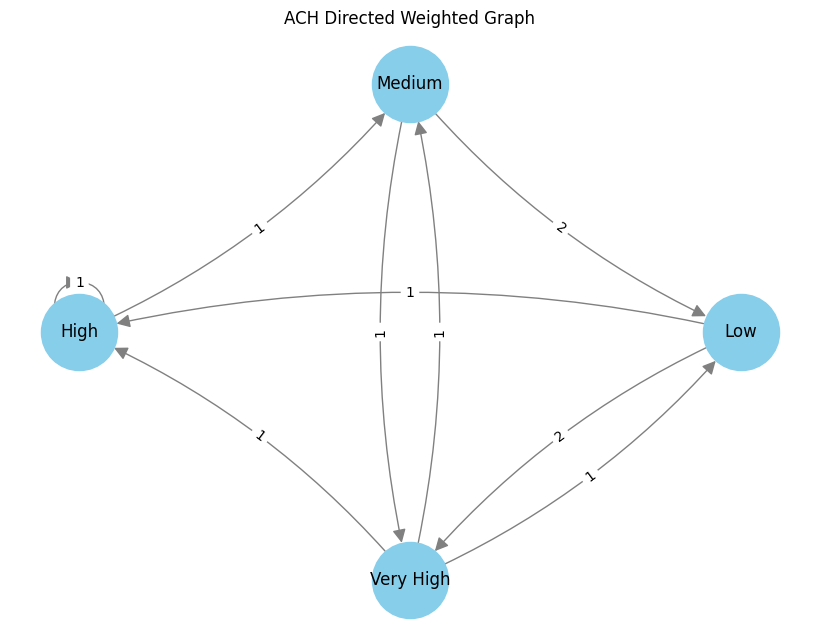

In [25]:
# Now we build the same graph again, except this time we keep the frequency as well.
WG = nx.DiGraph()
WG.add_nodes_from(nodes)

# The weight of an edge is how many times that move actually happened during the year, so atransition that repeated shows up as a heavier edge instead of just being listed once.
WG.add_weighted_edges_from([
    ("Medium", "Low", 2),
    ("Low", "High", 1),
    ("High", "Medium", 1),
    ("Medium", "Very High", 1),
    ("Very High", "Medium", 1),
    ("Low", "Very High", 2),
    ("Very High", "Low", 1),
    ("Very High", "High", 1),
    ("High", "High", 1)
])

# We draw it the same way as before, only now we also write the weight on each edge.
plt.figure(figsize=(8, 6))
pos = nx.circular_layout(WG)

nx.draw(
    WG,
    pos,
    with_labels=True,
    arrows=True,
    arrowsize=20,
    node_size=3000,
    node_color="skyblue",
    edge_color="gray",
    connectionstyle="arc3,rad=0.12"
)

edge_labels = nx.get_edge_attributes(WG, "weight")

nx.draw_networkx_edge_labels(
    WG,
    pos,
    edge_labels=edge_labels,
    connectionstyle="arc3,rad=0.12"
)

plt.title("ACH Directed Weighted Graph")
plt.show()

## Directed Weighted Graph Measures

In [26]:
# In-degree and out-degree
print("In-Degree")
for node, value in WG.in_degree():
    print(node, value)

print("\nOut-Degree")
for node, value in WG.out_degree():
    print(node, value)

In-Degree
Low 2
Medium 2
High 3
Very High 2

Out-Degree
Low 2
Medium 2
High 2
Very High 3


In [27]:
# PageRank again
pagerank = nx.pagerank(WG, alpha=1.0)

for node, value in pagerank.items():
    print(node, round(value, 3))

Low 0.231
Medium 0.231
High 0.308
Very High 0.231


In [28]:
# Closeness again
closeness = nx.closeness_centrality(WG.reverse(), distance="distance")

for node, value in closeness.items():
    print(node, round(value, 3))

Low 0.75
Medium 0.75
High 0.6
Very High 1.0


In [29]:
# And betweenness again, also using the distances.
betweenness = nx.betweenness_centrality(WG, weight="distance")

for node, value in betweenness.items():
    print(node, round(value, 3))

Low 0.083
Medium 0.333
High 0.083
Very High 0.167
